In [1]:
from nnAudio.features.cqt import CQT
import torch
import math
from matplotlib import pyplot as plt
import numpy as np
import lightning as L
import scipy
from collections import Counter
import librosa
import torchaudio

from murenn import MuReNNDirect,DTCWT,IDTCWT


In [2]:
HYPERPARAMS = {
    "sr": 16000,
    "seg_length": 1024,
    "win_length": 400,
    "n_mels": 8,
    "f_min": 64,
    "f_max": 8000,
    "hop_length": 256,
    "n_samples": 5000,
}
mel_params = {
            "sample_rate": HYPERPARAMS["sr"],
            "n_fft": 1024, #512+1 bins
            "win_length": HYPERPARAMS["win_length"],
            "hop_length": HYPERPARAMS["hop_length"],
            "f_min": HYPERPARAMS["f_min"],
            "f_max": HYPERPARAMS["f_max"],
            "n_mels": HYPERPARAMS["n_mels"], #averange o
            "center": False,
            "power": 2.0
        }
col = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
teacher = torchaudio.transforms.MelSpectrogram(**mel_params)
mel_fbank = teacher.mel_scale.fb.flip(dims=(-1,)) #nb_bins*nb_mels tensor

Counter({2: 2, 1: 2, 5: 1, 4: 1, 3: 1, 0: 1})

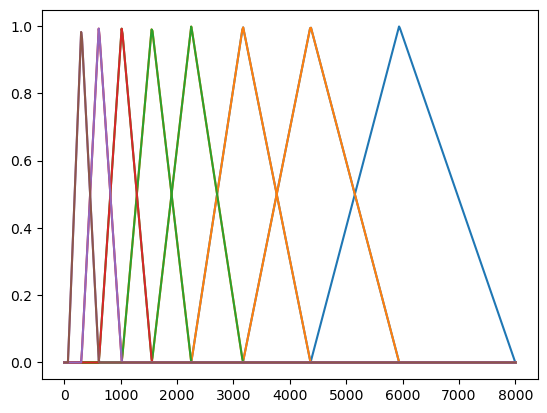

In [3]:
mel_scale = "htk"
# set x axis scale
m_min = torchaudio.functional.functional._hz_to_mel(
    teacher.f_min, mel_scale=mel_scale)
m_max = torchaudio.functional.functional._hz_to_mel(
    teacher.f_max, mel_scale=mel_scale)
# in mel scale
m_pts = torch.linspace(m_min, m_max, teacher.n_mels + 2)
# in freq(Hz) scale
f_pts = torchaudio.functional.functional._mel_to_hz(
    m_pts, mel_scale=mel_scale)
center_freqs = f_pts[1:-1]
nyquist = teacher.sample_rate / 2
octaves = np.round(np.log2(nyquist / center_freqs.numpy())).astype("int")  # Nyquist/2**(j+1)<epsilon_j<Nyquist/2**(j), -->log_2^(Nyquist/epsilon_j)-1<j<log_2^(Nyquist/epsilon_j)
Q_ctr = Counter(octaves) # filter per scale, sum = n_mels
J_psi = max(octaves)+1
boundaries = [0] + list(np.cumsum([Q_ctr[j] for j in range(J_psi)])) + [len(octaves)]
omega = np.linspace(0, teacher.sample_rate//2, mel_fbank.shape[0], endpoint=True)
for j in range(J_psi):
    psi_octave = mel_fbank[:, boundaries[j]:boundaries[j+2]]
    plt.plot(omega, psi_octave, color=col[j]);

HYPERPARAMS["n_octave"] = J_psi
HYPERPARAMS["octaves"] = Q_ctr
Q_ctr

In [6]:
class Student(L.LightningModule):
    def __init__(self, spec):
        super().__init__()
        self.spec = spec
        self.train_outputs = []
        self.test_outputs = []
        self.val_outputs = []
        self.loss = torch.nn.MSELoss()
        # self.loss = torch.nn.CosineSimilarity(dim=-1)

    def step(self, batch, fold):
        feat = batch[2]
        x = batch[1]
        Sx = self.forward(x)
        n_feat = feat.shape[-1]
        n_pred = Sx.shape[-1]
        N = min(n_feat, n_pred)
        # print(feat.shape)
        # print(Sx.shape)
        # loss = criterion(outputs[:,:,:N], feat[:,:,:N])
        # loss = 0.5 * (1-self.loss(Sx[:,:,:N], feat[:,:,:N]).mean())
        loss = self.loss(Sx, feat)
        if fold == "train":
            self.train_outputs.append(loss)
        elif fold == "test":
            self.test_outputs.append(loss)
        elif fold == "val":
            self.val_outputs.append(loss)
        return {'loss': loss}

    def get_imp_fig(self, x):
        fig = plt.figure()
        conv1d = self.tfm.to_conv1d
        path_idx = 0
        paths = conv1d(x)#.flip(dims=(-2,))
        for j in range(self.J_psi):
            for q in range(self.Q[j]):
                path = paths[0, path_idx, :]
                path_hat = torch.fft.fft(path, axis=-1)
                plt.plot(torch.abs(path_hat).cpu(), color=col[j])
                path_idx +=1
        return fig

    def training_step(self, batch, batch_idx):
        return self.step(batch, "train")
    
    def validation_step(self, batch, batch_idx):
        return self.step(batch, "val")

    def test_step(self, batch, batch_idx):
        return self.step(batch, "test")
    
    def on_train_epoch_start(self):
        self.train_outputs = []
        self.test_outputs = []
        self.val_outputs = []

    def on_train_epoch_end(self):
        avg_loss = torch.tensor(self.train_outputs).mean()
        self.log('train_loss', avg_loss, prog_bar=False)
    
    def on_test_epoch_end(self):
        avg_loss = torch.tensor(self.test_outputs).mean()
        self.log('test_loss', avg_loss, prog_bar=False)

    def on_validation_epoch_end(self):
        avg_loss = torch.tensor(self.val_outputs).mean()
        x =torch.zeros(1,1,self.spec["seg_length"], device='mps')
        x[:,:,x.shape[-1]//2] = 1
        fig = self.get_imp_fig(x)
        tensorboard = self.logger.experiment
        tensorboard.add_figure("imp response", fig, global_step = self.trainer.global_step)
        tensorboard.close()
        self.log('val_loss', avg_loss, prog_bar=False)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters())
class MuReNN(Student):
    def __init__(self, spec, Q_multiplier=16):
        super().__init__(spec)
        self.J_psi = spec["n_octave"]
        self.Q = spec["octaves"]
        self.tfm = MuReNNDirect(
            J = self.J_psi,
            Q = self.Q,
            T = Q_multiplier,
            in_channels = 1,
        )
        phi_kernel_size = teacher.n_fft // (2**self.J_psi) #dilation=2**J-->total kernel size = n_fft
        self.phi = torch.nn.Conv1d(
            in_channels=teacher.n_mels,
            out_channels=teacher.n_mels,
            kernel_size=phi_kernel_size,
            stride=teacher.hop_length // (2**self.J_psi), #total stride = 2**J*(hop_length)/(2**J)=hop length
            groups=teacher.n_mels,
            bias=False)

    def forward(self, x):
        x = x.reshape(x.shape[0],1,-1)
        x_levels = self.tfm(x) # B, C, Q, J, N
        # Ux = Ux.permute(0, 3, 2, 1, 4).reshape(Ux.shape[0], Ux.shape[2]*Ux.shape[3], -1).flip(dims=(-2,))
        x_levels = x_levels.reshape(x_levels.shape[0],x_levels.shape[2],-1).flip(dims=(-2,))
        Ux = self.phi(x_levels)
        return Ux

(0.5, 8000.0)

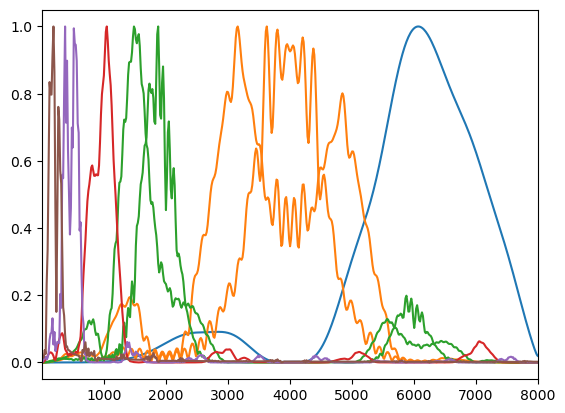

In [8]:
ckpt_pth = "/Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt/synth/0/last-v2.ckpt"
M = MuReNN.load_from_checkpoint(ckpt_pth,spec=HYPERPARAMS)
M.eval()
M.to('cpu')
Q = M.tfm.Q
J = M.tfm.dtcwt.J
N = 1024
conv1d = M.tfm.to_conv1d
x = torch.zeros(1,1,N)
x[:,:,N//2] = 1
y = conv1d(x).detach().flip(dims=(-2,))
omega = torch.linspace(0, HYPERPARAMS['sr'], N)
path_idx = -1
for j in range(J):
    for q in range(Q[j]):
        path = y[0,path_idx,:]
        path_hat = torch.fft.fft(path)
        plt.plot(omega, torch.abs(path_hat)/torch.max(torch.abs(path_hat)), color=col[j])
        path_idx -= 1
plt.xlim(0.5, HYPERPARAMS['sr']//2)